In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

base = pd.read_csv("../data/tratado/base_mensal.csv", parse_dates=["data"], index_col="data")
PASTA_FIG = Path("../figuras")

AZUL, LARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, MUTED = "#0b0b0b", "#52514e", "#898781"
FONTE = "Fonte: Banco Central do Brasil (SGS). Elaboração própria."
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 11,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": TINTA_2, "text.color": TINTA,
})

# Variações em 12 meses (em pontos percentuais): removem tendência e sazonalidade
dados = pd.DataFrame({
    "selic_d12": base["selic_meta"].diff(12),
    "pf_d12": base["inad_pf"].diff(12),
    "pj_d12": base["inad_pj"].diff(12),
})
ALVOS = {"PF": "pf_d12", "PJ": "pj_d12"}
dados.dropna().tail()

,selic_d12,pf_d12,pj_d12
data,,,
2026-05-01,-0.25,1.27,0.58
2026-06-01,-0.75,1.02,0.51
2026-07-01,-0.75,1.14,0.53
2026-08-01,-1.00,1.12,0.51
2026-09-01,-1.25,1.10,0.51


In [2]:
# Período afetado pela pandemia. Vai até dez/2022 porque a variação em 12 meses
# "carrega" a distorção de 2021 por mais 12 meses.
AFETADO = ("2020-03-01", "2022-12-01")

def afetado(datas):
    return (datas >= AFETADO[0]) & (datas <= AFETADO[1])

def correlacao_defasada(alvo, max_lag=24, excluir_pandemia=False):
    """Correlação entre a variação da Selic em t e a da inadimplência em t + lag."""
    linhas = []
    for lag in range(max_lag + 1):
        par = pd.DataFrame({"x": dados["selic_d12"], "y": dados[alvo].shift(-lag)}).dropna()
        if excluir_pandemia:
            fora = afetado(par.index) | afetado(par.index + pd.DateOffset(months=lag))
            par = par[~fora]
        linhas.append({"lag": lag, "corr": par["x"].corr(par["y"]), "n": len(par)})
    return pd.DataFrame(linhas).set_index("lag")

In [3]:
tabela = pd.DataFrame({
    "PF": correlacao_defasada("pf_d12")["corr"],
    "PJ": correlacao_defasada("pj_d12")["corr"],
    "PF sem pandemia": correlacao_defasada("pf_d12", excluir_pandemia=True)["corr"],
    "PJ sem pandemia": correlacao_defasada("pj_d12", excluir_pandemia=True)["corr"],
}).round(2)

print(tabela.to_string())
print("\nDefasagem com a maior correlação:")
print(pd.DataFrame({"lag (meses)": tabela.idxmax(), "correlação": tabela.max()}).to_string())

       PF    PJ  PF sem pandemia  PJ sem pandemia
lag                                              
0    0.35  0.22             0.28             0.19
1    0.42  0.31             0.34             0.29
2    0.49  0.39             0.40             0.39
3    0.54  0.47             0.45             0.48
4    0.59  0.54             0.49             0.57
5    0.62  0.61             0.51             0.64
6    0.63  0.66             0.52             0.70
7    0.64  0.70             0.51             0.75
8    0.63  0.73             0.49             0.79
9    0.60  0.76             0.46             0.81
10   0.56  0.77             0.41             0.81
11   0.50  0.77             0.36             0.81
12   0.43  0.77             0.29             0.79
13   0.36  0.75             0.22             0.76
14   0.27  0.73             0.15             0.72
15   0.19  0.70             0.08             0.67
16   0.10  0.67             0.01             0.62
17   0.01  0.62            -0.05             0.56


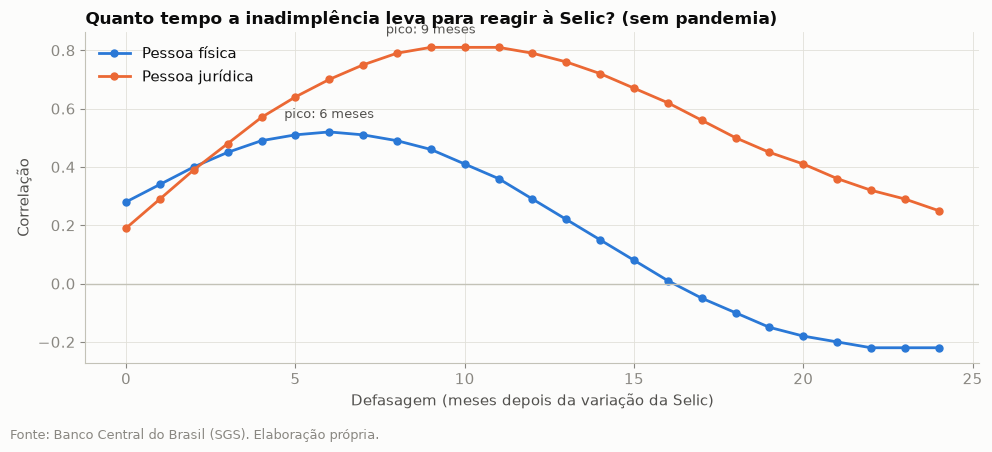

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for nome, cor, rotulo in [("PF", AZUL, "Pessoa física"), ("PJ", LARANJA, "Pessoa jurídica")]:
    s = tabela[f"{nome} sem pandemia"]
    ax.plot(s.index, s, color=cor, marker="o", markersize=5, label=rotulo)
    ax.annotate(f"pico: {s.idxmax()} meses", (s.idxmax(), s.max()), xytext=(0, 10),
                textcoords="offset points", ha="center", fontsize=9, color=TINTA_2)
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("Defasagem (meses depois da variação da Selic)")
ax.set_ylabel("Correlação")
ax.set_title("Quanto tempo a inadimplência leva para reagir à Selic? (sem pandemia)")
ax.legend(frameon=False, loc="upper left")
fig.text(0.01, 0.01, FONTE, fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(PASTA_FIG / "04_correlacao_defasada.png", dpi=150)
plt.show()

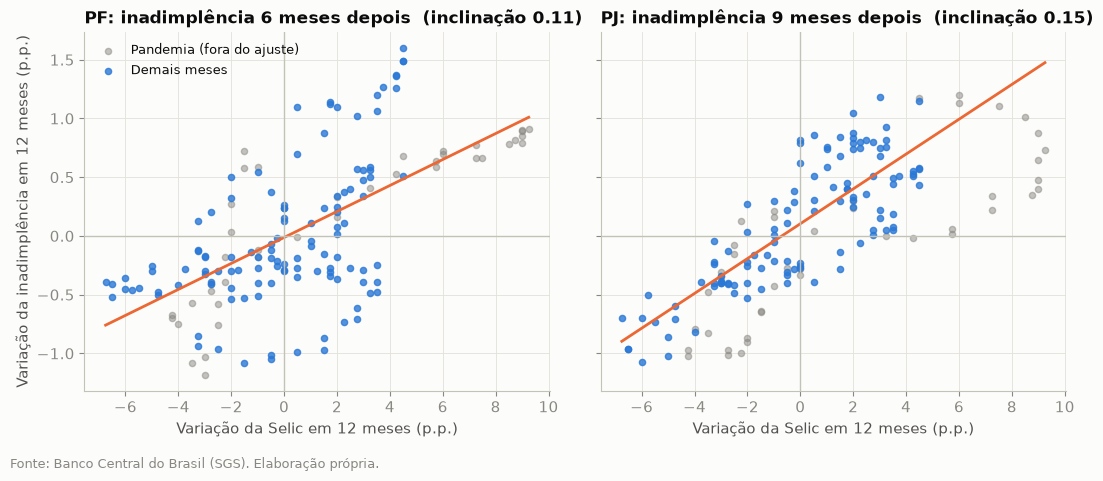

,lag (meses),inclinação,correlação,n
PF,6.0,0.111,0.52,119.0
PJ,9.0,0.148,0.81,113.0


In [5]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.8), sharex=True, sharey=True)
resultados = {}

for ax, (nome, alvo) in zip(eixos, ALVOS.items()):
    lag = int(tabela[f"{nome} sem pandemia"].idxmax())
    par = pd.DataFrame({"x": dados["selic_d12"], "y": dados[alvo].shift(-lag)}).dropna()
    fora = afetado(par.index) | afetado(par.index + pd.DateOffset(months=lag))
    normal = par[~fora]

    inclinacao, intercepto = np.polyfit(normal["x"], normal["y"], 1)
    resultados[nome] = {"lag (meses)": lag, "inclinação": round(inclinacao, 3),
                        "correlação": round(normal["x"].corr(normal["y"]), 2), "n": len(normal)}

    ax.scatter(par.loc[fora, "x"], par.loc[fora, "y"], s=20, color=MUTED, alpha=0.5,
               label="Pandemia (fora do ajuste)")
    ax.scatter(normal["x"], normal["y"], s=20, color=AZUL, alpha=0.8, label="Demais meses")
    xs = np.linspace(par["x"].min(), par["x"].max(), 50)
    ax.plot(xs, inclinacao * xs + intercepto, color=LARANJA)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.axvline(0, color="#c3c2b7", lw=1)
    ax.set_title(f"{nome}: inadimplência {lag} meses depois  (inclinação {inclinacao:.2f})")
    ax.set_xlabel("Variação da Selic em 12 meses (p.p.)")

eixos[0].set_ylabel("Variação da inadimplência em 12 meses (p.p.)")
eixos[0].legend(frameon=False, fontsize=9, loc="upper left")
fig.text(0.01, 0.01, FONTE, fontsize=9, color=MUTED)
fig.tight_layout(rect=[0, 0.04, 1, 1])
fig.savefig(PASTA_FIG / "05_sensibilidade_pf_pj.png", dpi=150)
plt.show()

pd.DataFrame(resultados).T

## Conclusões

### Hipótese 1 — Defasagem: confirmada
A correlação entre a variação da Selic em 12 meses e a da inadimplência é máxima com defasagem de
**6 meses para PF** (0,52) e **9 meses para PJ** (0,81), excluindo o período da pandemia. A leitura
visual da análise exploratória (6–7 meses para PF) foi confirmada.

### Hipótese 2 — "PF é mais sensível à Selic": rejeitada
| | Defasagem | Inclinação | Correlação | R² |
|---|---|---|---|---|
| PF | 6 meses | 0,111 | 0,52 | 0,27 |
| PJ | 9 meses | 0,148 | 0,81 | 0,66 |

A PF reage **mais rápido**, mas a PJ reage com **mais intensidade e consistência**: uma alta de 4 p.p.
na Selic associa-se a +0,44 p.p. de inadimplência PF (6 meses depois) e +0,59 p.p. PJ (9 meses depois).
Interpretação: o crédito PJ é em boa parte pós-fixado, mas empresas têm caixa, garantias e capacidade
de renegociar, e demoram mais para atrasar. A inadimplência PF depende também de emprego, renda e
endividamento — a Selic acompanha apenas ~27% da sua variação.

### Hipótese 3 — Robustez sem pandemia: confirmada, com ressalva
Excluindo mar/2020–dez/2022, a relação PJ se fortalece (0,77 → 0,81) e a PF enfraquece (0,64 → 0,52):
a pandemia inflava a correlação PF, pois Selic e inadimplência caíram juntas em 2020 por causas
diferentes (corte de juros × carências e renegociações). A versão sem pandemia é a principal.

### Achado principal: a alta recente da inadimplência PF não é explicada pela Selic
Aplicando as inclinações históricas ao ciclo de alta de 2024–2025 (~+4,5 p.p.), a relação prevê cerca
de +0,5 p.p. para PF e +0,7 p.p. para PJ. A PJ subiu +0,78 p.p., em linha com o histórico; a PF subiu
+2,24 p.p., cerca de 4 vezes o esperado. Algo além dos juros pressiona as famílias desde 2025 —
candidatos: endividamento e comprometimento de renda, e possíveis efeitos da Resolução CMN 4.966.

### Observação
A correlação PF fica negativa a partir de ~17 meses: após um ciclo de alta, a inadimplência das famílias
tende a cair, possivelmente porque os bancos restringem crédito a perfis de risco e porque os ciclos da
Selic se revertem. Com poucos ciclos, isso é uma observação, não uma conclusão.

### Limitações
- As variações em 12 meses se sobrepõem: os ~115 pontos não são independentes, e a amostra contém na
  prática 3–4 ciclos da Selic. Os resultados indicam direção e defasagem, não prova estatística.
- Relação bivariada: não controla emprego, renda, endividamento nem programas de renegociação.
- Correlação não implica causalidade.

### Próximos passos da análise
Incluir séries de endividamento e comprometimento de renda das famílias (SGS) para investigar a alta
da inadimplência PF não explicada pela Selic.